# 영양 모델 학습 결과 (AIHub 122 음식분류 109종)

`configs/cls109_nutrition.yaml` 로 학습한 Stage3 영양 모델(Gemini 텍스트 임베딩 + 이미지·주파수 특징)의 결과.

- 텍스트: `"{food_name} (재료: {ingredients})"` — 파이프라인(`pipeline_infer`)과 같은 형식. 재료는 Gemini 로 생성.
- 정답: 영양DB 1인분(Q4) 값. 음식분류 사진은 양 정보가 없어 **같은 음식의 사진은 정답이 모두 같다.**
- 분할은 음식 단위로 떼어 두었다: 검증(조기 종료) = 처음 보는 10종, test_seen = 학습한 음식의 test 사진,
  test_unseen = 처음 보는 16종.
- 지표 PMAE = 100 × MAE / 정답 평균 (%), mean_pmae = 칼로리·지방·단백질 PMAE 평균.

1. 데이터 분할 · 2. 학습 곡선 · 3. 테스트 성능 비교 · 4. 처음 보는 음식별 예측 · 5. 학습한 음식 예측 · 6. 파이프라인 예시

그림은 `runs/nutrition_cls109/figures/` 에도 저장한다.

In [1]:
import os, sys, json
ROOT = "/home/students/cs/202321024/2025_2/diet-management/n296_stage3"
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from IPython.display import display
from n296.common import load_config, resolve, TARGETS
from n296.metrics import compute_metrics

cfg = load_config("configs/cls109_nutrition.yaml")
RUN = resolve("runs/nutrition_cls109")
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e8e7e3"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
mpl.rcParams.update({
    "font.family": "Noto Sans CJK JP", "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

d = cfg["data"]
main = pd.read_csv(resolve(cfg["paths"]["manifest"]))
db = pd.read_csv(resolve(cfg["paths"]["text_only_manifest"]))
seen = pd.read_csv(resolve(d["test_seen_manifest"]))
unseen = pd.read_csv(resolve(d["test_unseen_manifest"]))

## 1. 데이터 분할

In [2]:
tr, va = main[main.source_split == "Training"], main[main.source_split == "Validation"]
tab = pd.DataFrame({
    "음식 수": [tr.food_name.nunique(), va.food_name.nunique(), seen.food_name.nunique(), unseen.food_name.nunique(), len(db)],
    "사진 수": [len(tr), len(va), len(seen), len(unseen), 0],
    "역할": ["학습", "조기 종료 기준 (처음 보는 음식)", "테스트: 학습한 음식의 다른 사진", "테스트: 처음 보는 음식", "학습 (이미지 없는 텍스트 샘플)"],
}, index=["train", "val", "test_seen", "test_unseen", "텍스트 전용(영양DB)"])
display(tab)
print("val 음식:", sorted(va.food_name.unique()))
print("test_unseen 음식:", sorted(unseen.food_name.unique()))
print("텍스트 예:", tr.iloc[0].food_name, "(재료:", tr.iloc[0].ingredients + ")")

,음식 수,사진 수,역할
train,83,14754,학습
val,10,2014,조기 종료 기준 (처음 보는 음식)
test_seen,83,1641,테스트: 학습한 음식의 다른 사진
test_unseen,16,3130,테스트: 처음 보는 음식
텍스트 전용(영양DB),374,0,학습 (이미지 없는 텍스트 샘플)


val 음식: ['감자튀김', '꽁치조림', '달걀찜', '물냉면', '삼선자장면', '열무김치국수', '잔치국수', '잣죽', '조기조림', '치킨가스']
test_unseen 음식: ['갈치조림', '기스면', '김치말이국수', '깐풍기', '동태조림', '만둣국', '모래집튀김', '북어조림', '소갈비찜', '쌀국수', '쥐포튀김', '참꼬막', '콘스프', '토마토소스스파게티', '토마토스프', '회냉면']
텍스트 예: 돈가스 (재료: 돼지고기, 밀가루, 달걀, 빵가루, 식용유, 소금, 후추)


## 2. 학습 곡선

1단계(텍스트) → 2단계(이미지) → 3단계(결합). 각 단계는 앞 단계의 best 가중치에서 시작한다. 검증 오차는 **처음 보는 음식 10종** 기준이다.

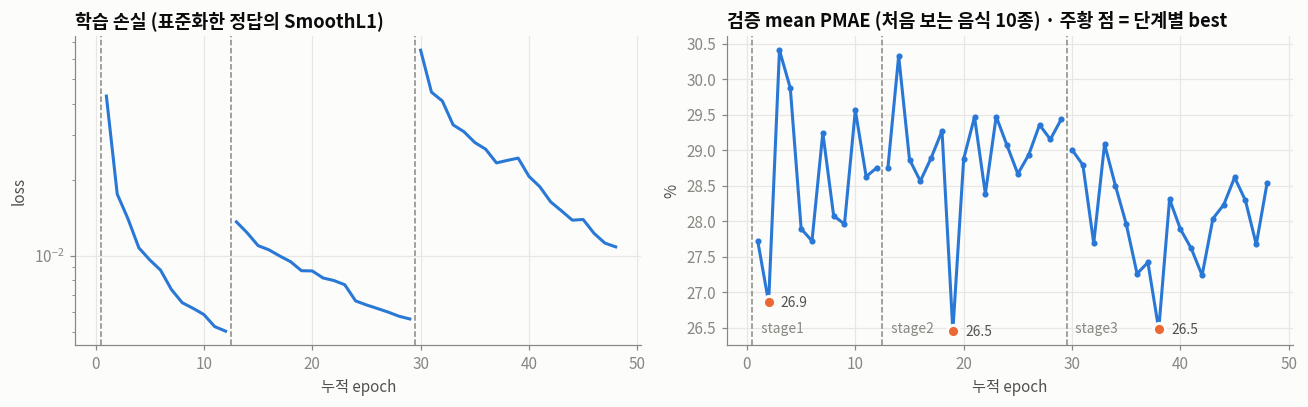

,epoch,cal,fat,prot,mass,carb_head,mean_pmae
stage,,,,,,,
stage1_text,2,22.00,34.33,24.24,23.35,19.54,26.86
stage2_image,7,21.61,34.54,23.21,19.92,18.31,26.45
stage3_fusion,9,20.75,34.18,24.50,21.08,18.31,26.48


In [3]:
h = pd.read_csv(RUN / "history.csv")
h["step"] = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (name, g) in enumerate(h.groupby("stage", sort=False)):
    ax[0].plot(g.step, g.train_loss, color=C1)
    ax[1].plot(g.step, g.mean_pmae, color=C1, marker="o", ms=3)
    for a in ax:
        a.axvline(g.step.min() - 0.5, color=MUTED, lw=1, ls="--")
    b = g.loc[g.mean_pmae.idxmin()]
    ax[1].text(g.step.min(), 0.03, f" {name.split('_')[0]}", color=MUTED, va="bottom", fontsize=9, transform=ax[1].get_xaxis_transform())
    ax[1].plot(b.step, b.mean_pmae, "o", color=C2, ms=8, mec=SURFACE, mew=2)
    ax[1].annotate(f"{b.mean_pmae:.1f}", (b.step, b.mean_pmae), xytext=(8, -3), textcoords="offset points", ha="left", color=INK2, fontsize=9)
ax[0].set(title="학습 손실 (표준화한 정답의 SmoothL1)", xlabel="누적 epoch", ylabel="loss", yscale="log")
ax[1].set(title="검증 mean PMAE (처음 보는 음식 10종) · 주황 점 = 단계별 best", xlabel="누적 epoch", ylabel="%")
fig.tight_layout(); save(fig, "01_learning_curve"); plt.show()
display(h.loc[h.groupby("stage", sort=False).mean_pmae.idxmin(), ["stage", "epoch", "cal", "fat", "prot", "mass", "carb_head", "mean_pmae"]].round(2).set_index("stage"))

## 3. 테스트 성능 비교

- **평균값 예측**: 학습 사진 정답의 평균을 모든 사진에 예측 (아무것도 배우지 않은 기준선)
- **텍스트만**: 이미지 분기를 mask 토큰으로 대체 (`--image-mode masked`)
- **텍스트 + 이미지**: 실제 파이프라인과 같은 입력

cal   fat  prot  mass  carb_head  mean_pmae
test        입력                                                     
test_seen   평균값 예측     44.9  67.4  57.3  67.8       63.1       56.6
            텍스트만        2.2   3.4   2.2   2.7        3.1        2.6
            텍스트 + 이미지   2.9   4.5   4.0   4.0        3.9        3.8
test_unseen 평균값 예측     42.3  63.2  39.1  61.0       79.9       48.2
            텍스트만       42.1  60.4  40.8  19.6       46.1       47.8
            텍스트 + 이미지  39.4  53.9  37.9  18.9       47.1       43.8

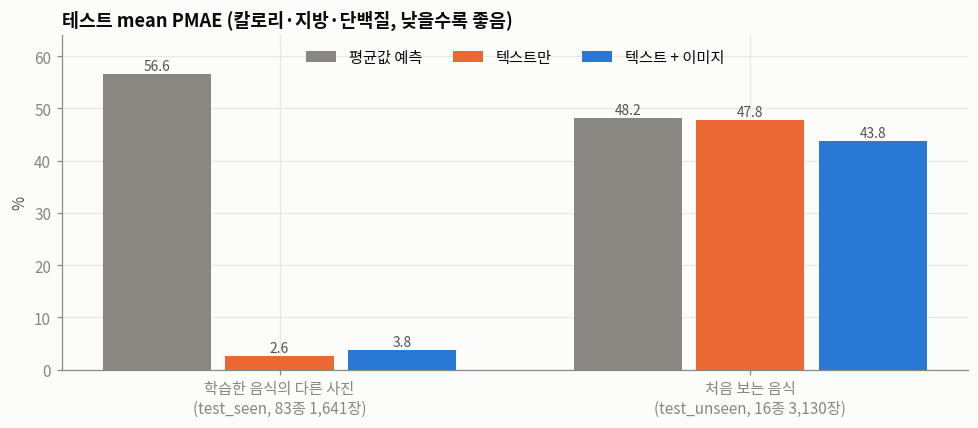

In [4]:
def metrics_of(csv):
    r = pd.read_csv(csv)
    return compute_metrics({k: r[f"pred_{k}"].values for k in TARGETS}, {k: r[f"gt_{k}"].values for k in TARGETS})

def baseline(test):
    pred = {k: np.full(len(test), tr[k].mean()) for k in TARGETS}
    return compute_metrics(pred, {k: test[k].values for k in TARGETS})

rows = []
for name, test in (("test_seen", seen), ("test_unseen", unseen)):
    for label, m in (("평균값 예측", baseline(test)),
                     ("텍스트만", metrics_of(RUN / f"eval_{name}_masked.csv")),
                     ("텍스트 + 이미지", metrics_of(RUN / f"eval_{name}_full.csv"))):
        rows.append({"test": name, "입력": label, **{k: m[k] for k in ("cal", "fat", "prot", "mass", "carb_head", "mean_pmae")}})
res = pd.DataFrame(rows)
display(res.round(1).set_index(["test", "입력"]))

fig, ax = plt.subplots(figsize=(9, 4))
labels = ["평균값 예측", "텍스트만", "텍스트 + 이미지"]
colors = [MUTED, C2, C1]
x = np.arange(2); w = 0.26
for i, (lab, c) in enumerate(zip(labels, colors)):
    v = [res[(res.test == t) & (res.입력 == lab)].mean_pmae.item() for t in ("test_seen", "test_unseen")]
    bars = ax.bar(x + (i - 1) * w, v, w - 0.03, color=c, label=lab)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.8, f"{val:.1f}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, ["학습한 음식의 다른 사진\n(test_seen, 83종 1,641장)", "처음 보는 음식\n(test_unseen, 16종 3,130장)"])
ax.set(title="테스트 mean PMAE (칼로리·지방·단백질, 낮을수록 좋음)", ylabel="%")
ax.set_ylim(0, 64)
ax.legend(frameon=False, loc="upper center", ncol=3)
fig.tight_layout(); save(fig, "02_test_pmae"); plt.show()

## 4. 처음 보는 음식별 칼로리 예측

회색 점 = 영양DB 정답, 파란 점 = 사진별 예측의 평균 (선 = 오차).

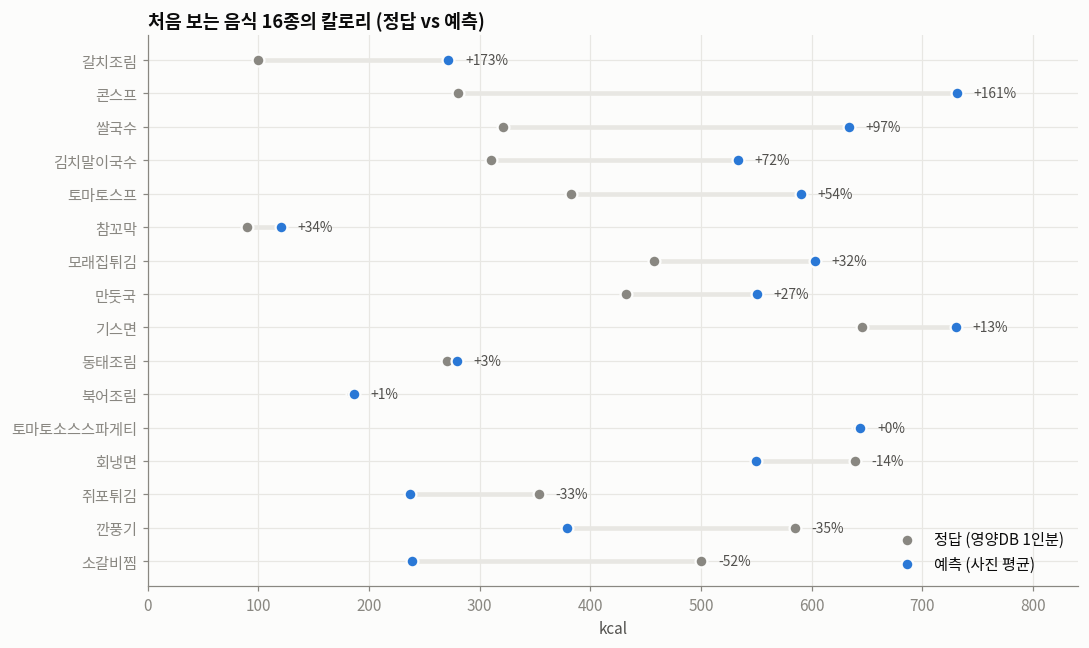

사진별 예측의 음식 내 표준편차 평균: 10.4 kcal (정답은 음식마다 하나)


,정답 kcal,예측 kcal,예측 표준편차,정답 g,예측 g,칼로리 오차 %
food_name,,,,,,
소갈비찜,500.0,239.0,14.0,250.0,155.0,-52.0
깐풍기,585.0,379.0,6.0,200.0,175.0,-35.0
쥐포튀김,353.0,237.0,41.0,100.0,133.0,-33.0
회냉면,639.0,550.0,8.0,550.0,516.0,-14.0
토마토소스스파게티,642.0,644.0,9.0,500.0,433.0,0.0
북어조림,185.0,186.0,9.0,100.0,155.0,1.0
동태조림,271.0,279.0,13.0,250.0,277.0,3.0
기스면,646.0,730.0,9.0,1000.0,831.0,13.0
만둣국,433.0,551.0,4.0,700.0,626.0,27.0


In [5]:
u = pd.read_csv(RUN / "eval_test_unseen_full.csv")
g = u.groupby("food_name").agg(kcal_gt=("gt_calories", "first"), kcal_pred=("pred_calories", "mean"), sd=("pred_calories", "std"),
                               gt_mass=("gt_mass", "first"), pred_mass=("pred_mass", "mean")).reset_index()
g["err"] = 100 * (g.kcal_pred - g.kcal_gt) / g.kcal_gt
g = g.sort_values("err").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 6))
for i, r in g.iterrows():
    ax.plot([r.kcal_gt, r.kcal_pred], [i, i], color=GRID, lw=3, solid_capstyle="round", zorder=1)
ax.scatter(g.kcal_gt, g.index, color=MUTED, s=60, zorder=2, label="정답 (영양DB 1인분)", edgecolor=SURFACE, lw=1.5)
ax.scatter(g.kcal_pred, g.index, color=C1, s=60, zorder=3, label="예측 (사진 평균)", edgecolor=SURFACE, lw=1.5)
for i, r in g.iterrows():
    ax.text(max(r.kcal_gt, r.kcal_pred) + 15, i, f"{r.err:+.0f}%", va="center", color=INK2, fontsize=9)
ax.set_yticks(g.index, g.food_name)
ax.set(title="처음 보는 음식 16종의 칼로리 (정답 vs 예측)", xlabel="kcal", xlim=(0, g[["kcal_gt", "kcal_pred"]].values.max() * 1.15))
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); save(fig, "03_unseen_per_food"); plt.show()
print(f"사진별 예측의 음식 내 표준편차 평균: {g.sd.mean():.1f} kcal (정답은 음식마다 하나)")
display(g.round(0).rename(columns={"kcal_gt": "정답 kcal", "kcal_pred": "예측 kcal", "sd": "예측 표준편차", "gt_mass": "정답 g", "pred_mass": "예측 g", "err": "칼로리 오차 %"}).set_index("food_name"))

## 5. 학습한 음식의 다른 사진 (test_seen)

음식마다 정답이 하나라 사실상 '음식 → 1인분 영양값'을 외운 결과다.

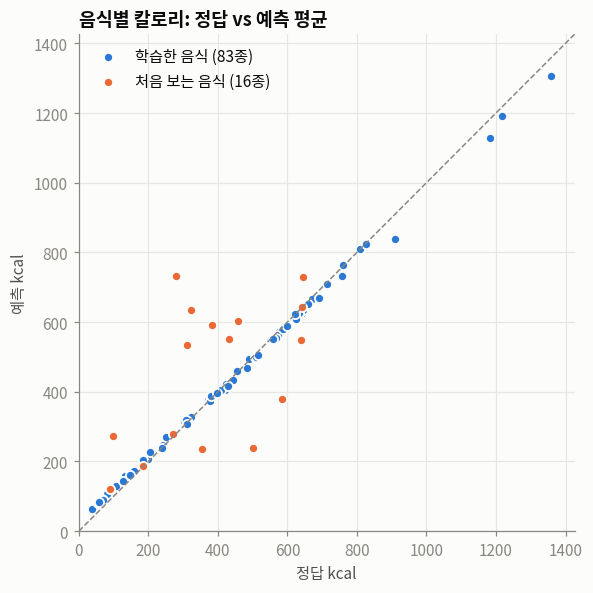

In [6]:
s = pd.read_csv(RUN / "eval_test_seen_full.csv")
gs = s.groupby("food_name").agg(kcal_gt=("gt_calories", "first"), kcal_pred=("pred_calories", "mean"))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = gs.values.max() * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1)
ax.scatter(gs.kcal_gt, gs.kcal_pred, color=C1, s=36, edgecolor=SURFACE, lw=1.2, label="학습한 음식 (83종)")
ax.scatter(g.kcal_gt, g.kcal_pred, color=C2, s=36, edgecolor=SURFACE, lw=1.2, label="처음 보는 음식 (16종)")
ax.set(title="음식별 칼로리: 정답 vs 예측 평균", xlabel="정답 kcal", ylabel="예측 kcal", xlim=(0, lim), ylim=(0, lim))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); save(fig, "04_seen_vs_unseen_scatter"); plt.show()

## 6. 파이프라인 예시

분류기/Gemini 음식명 → Gemini 재료 → 이 영양 모델 (`runs/pipeline_smoke2`).

In [7]:
r = pd.read_json(resolve("runs/pipeline_smoke2/pipeline_results.json"))
r["image"] = r["image_path"].str.split("/").str[-1]
display(r[["image", "cls_name", "cls_prob", "name_source", "food_name", "ingredients", "pred_calories", "pred_mass", "pred_fat", "pred_carb", "pred_protein"]].round(2))

,image,cls_name,cls_prob,name_source,food_name,ingredients,pred_calories,pred_mass,pred_fat,pred_carb,pred_protein
0,10_102_10012003_160678781933652_0.jpg,돈가스,0.69,gemini,돈가스,"[돼지고기, 밀가루, 달걀, 빵가루, 식용유]",602.85,212.40,37.05,41.03,25.76
1,A_13_A13010_대하구이_02_01.jpg,꽁치조림,0.23,gemini,새우구이,"[새우, 소금]",150.56,108.78,6.44,13.30,9.84
